# Reaction-Diffusion: multi-fidelity approaches with SDNs

Preliminary 2D parametric study before the TRIGA neutronics application. A nonlinear reaction-diffusion problem is solved with LF and HF models (LF misses part of the source). For $(u,v)$ on $\Omega=[0,1]^2$ with homogeneous Dirichlet BC:

$$
\begin{array}{ll}
\Delta u + (1-(u^2+v^2))\cdot u + \mu_1 \cdot (u^2+v^2) \cdot v = f(\mathbf{x};\mu_1,\mu_2) \\
\Delta v + (1-(u^2+v^2))\cdot v - \mu_1 \cdot (u^2+v^2) \cdot u = 0
\end{array}
$$

$$
f_{LF}(\mathbf{x};\mu_1,\mu_2)=\exp\!\left(-\frac{(x_0-0.6)^2+(x_1-0.2-\mu_2/200)^2}{0.01}\right),\quad
f_{HF}=f_{LF}+2\exp\!\left(-\frac{\|\mathbf{x}-\mathbf{c}(\mu_1,\mu_2)\|}{0.05}\right).
$$

**Parameters:** $\mu_1$ controls nonlinear coupling, $\mu_2$ shifts the LF source. Both are sampled in $[50,100]^2$ via Latin hypercube sampling. Snapshots use a finite-difference discretisation (`scipy.sparse`).


Let us solve a reaction diffusion problem

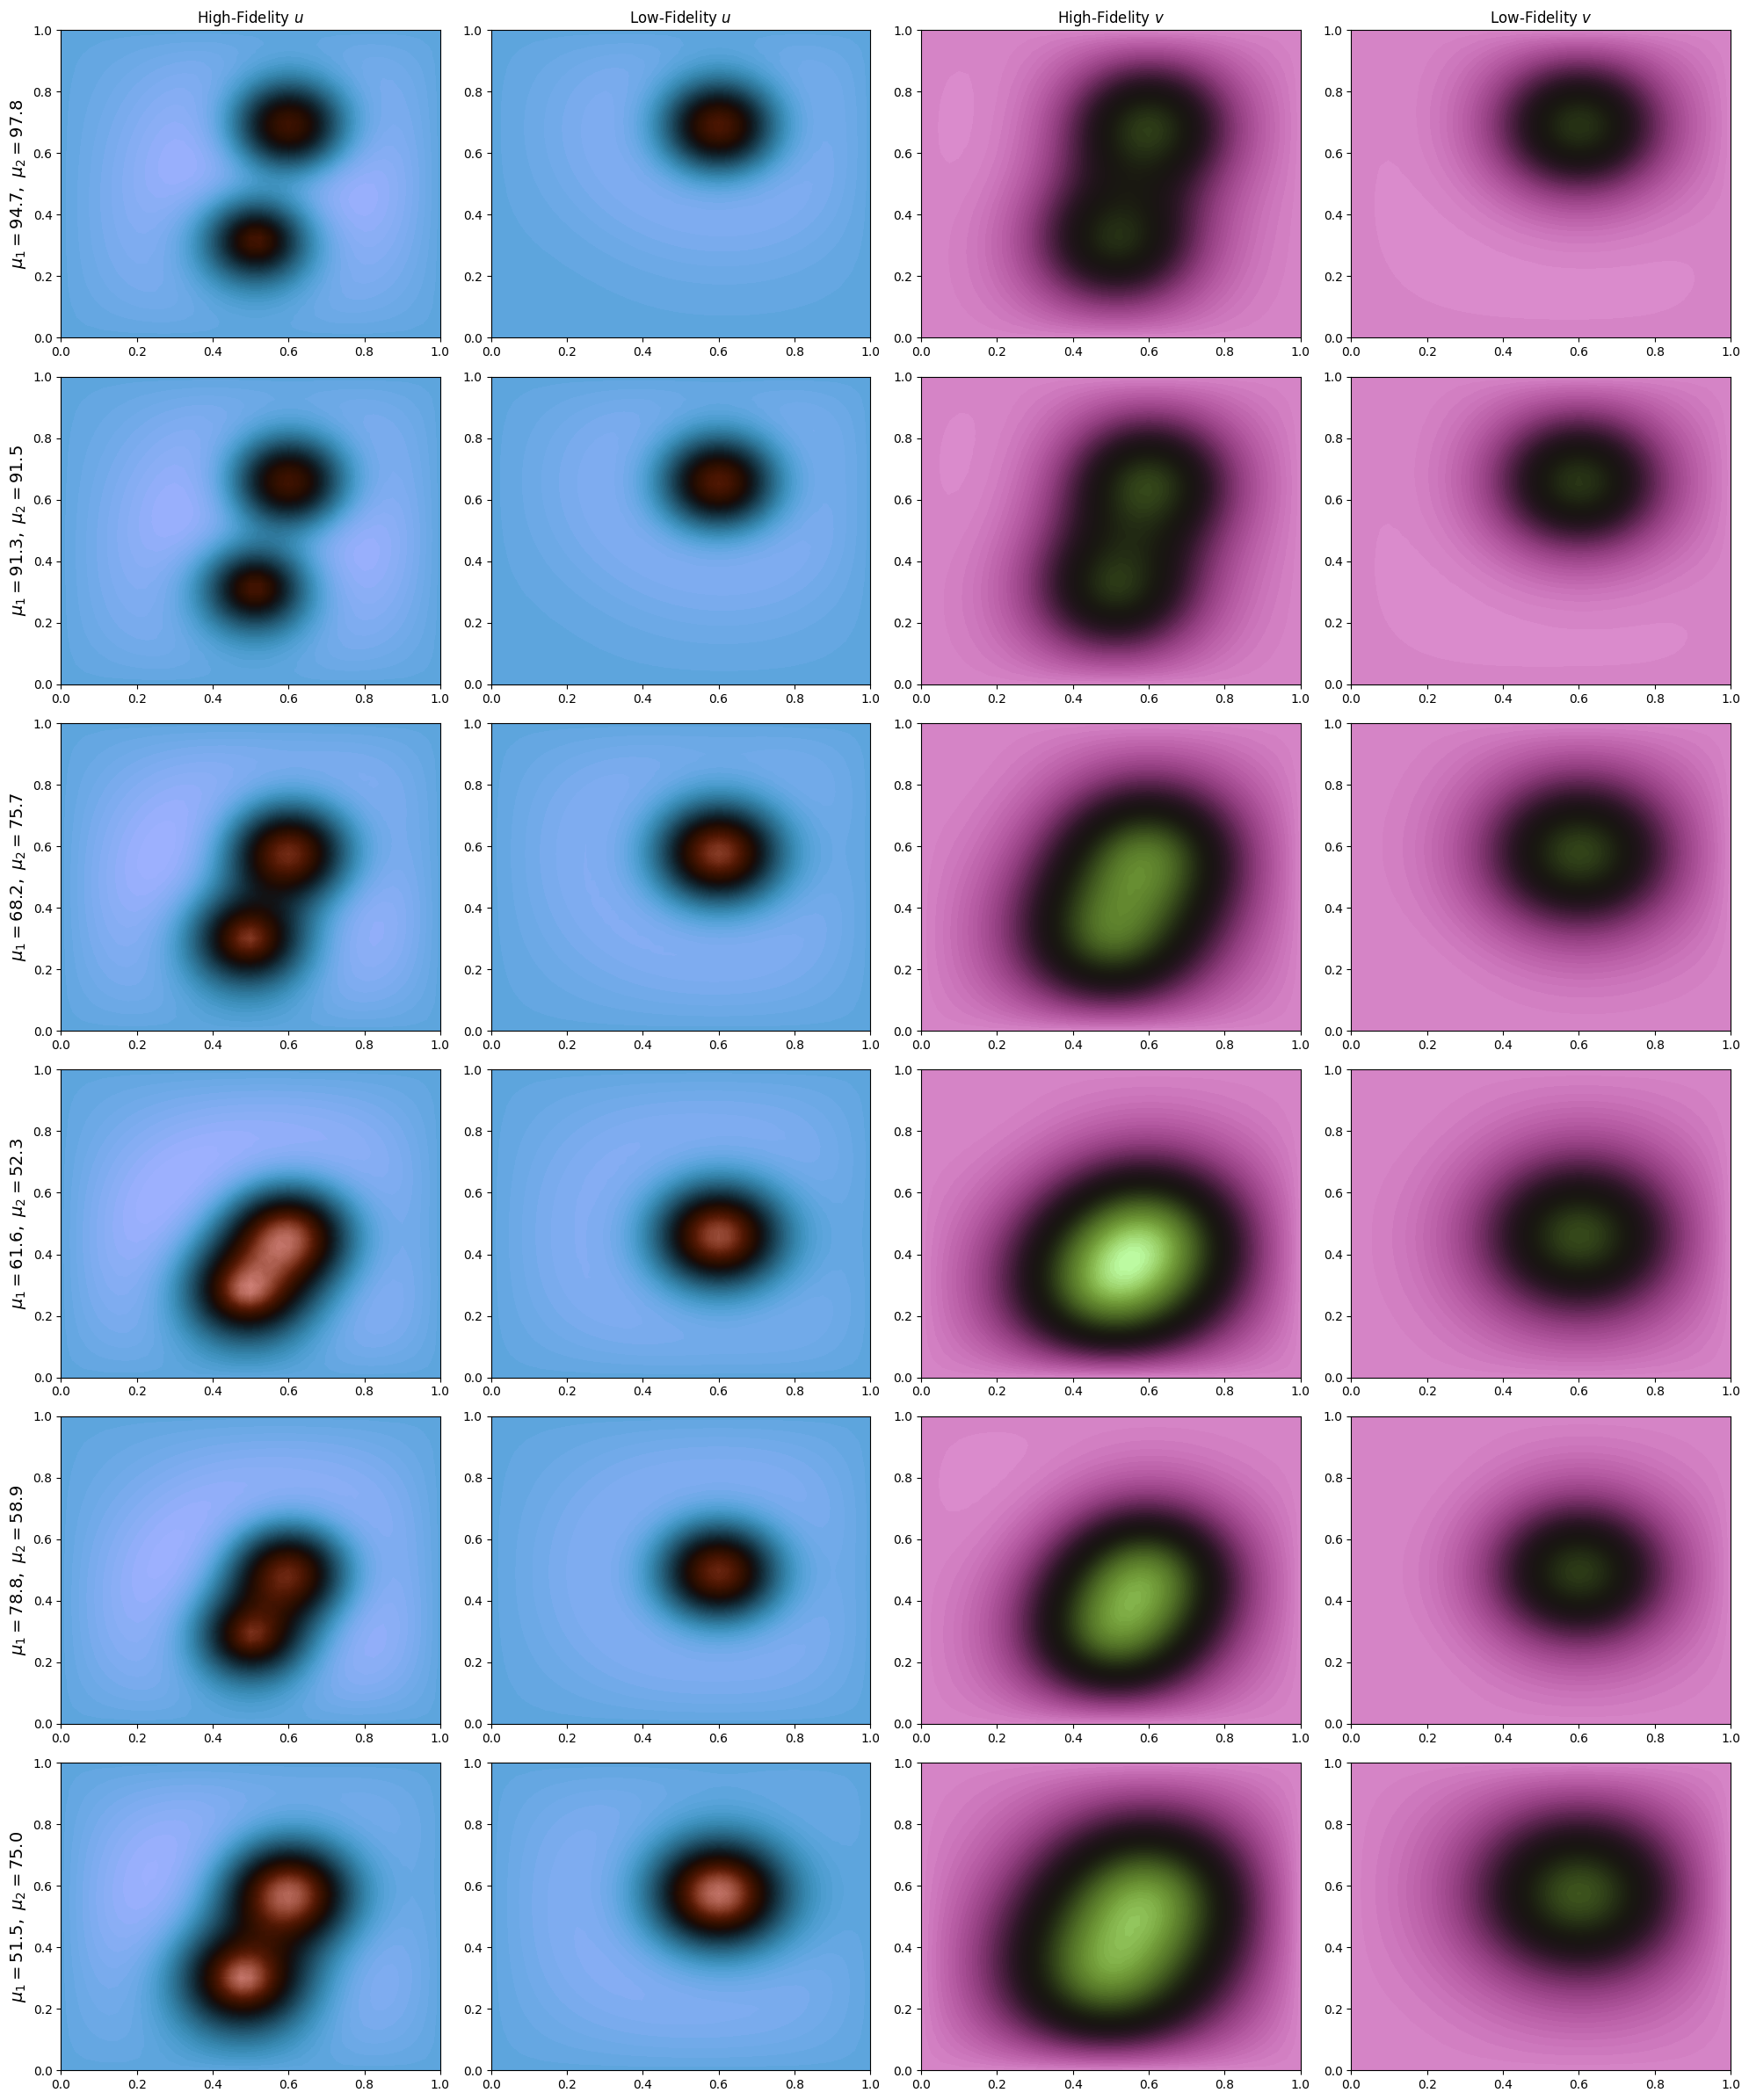

In [2]:
import sys
sys.path.append('..')
from utils.reaction_diffusion_2d import solve, sample_parameters

import numpy as np
from IPython.display import clear_output as clc

import matplotlib.pyplot as plt
from matplotlib import cm

PARAM_BOUNDS = ((50.0, 100.0), (50.0, 100.0))
N_LF_SAMPLES = 300
N_HF_SAMPLES = 200
N_PREVIEW = 6

param_preview = sample_parameters(N_PREVIEW, bounds=PARAM_BOUNDS, seed=0)
u_HF, u_LF = [], []
for mu1, mu2 in param_preview:
    print(f'Solving preview: mu1={mu1:.1f}, mu2={mu2:.1f}')
    sol, domain = solve(mu1=mu1, mu2=mu2, hf=True)
    u_HF.append(sol)
    sol, _ = solve(mu1=mu1, mu2=mu2, hf=False)
    u_LF.append(sol)
    clc()

u_HF = np.array(u_HF)
u_LF = np.array(u_LF)

_min = u_HF.min()
_max = u_HF.max()
u_HF = (u_HF - _min) / (_max - _min)
u_LF = (u_LF - _min) / (_max - _min)

fig, axs = plt.subplots(N_PREVIEW, 4, figsize=(5 * 4, 4 * N_PREVIEW))
cmaps = [cm.berlin, cm.vanimo]
levels = np.linspace(0, 1, 100)

for ii, (mu1, mu2) in enumerate(param_preview):
    axs[ii, 0].tricontourf(domain[:, 0], domain[:, 1], u_HF[ii, ::2], levels=levels, cmap=cmaps[0])
    axs[ii, 1].tricontourf(domain[:, 0], domain[:, 1], u_LF[ii, ::2], levels=levels, cmap=cmaps[0])
    axs[ii, 2].tricontourf(domain[:, 0], domain[:, 1], u_HF[ii, 1::2], levels=levels, cmap=cmaps[1])
    axs[ii, 3].tricontourf(domain[:, 0], domain[:, 1], u_LF[ii, 1::2], levels=levels, cmap=cmaps[1])
    axs[ii, 0].set_ylabel(rf'$\mu_1={mu1:.1f},\ \mu_2={mu2:.1f}$', fontsize=14)

axs[0, 0].set_title('High-Fidelity $u$')
axs[0, 1].set_title('Low-Fidelity $u$')
axs[0, 2].set_title('High-Fidelity $v$')
axs[0, 3].set_title('Low-Fidelity $v$')
plt.tight_layout()
plt.show()


## Low Fidelity Surrogate Model
A Shallow Decoder Network is trained to map the parameter and 3 random measurements to the full state (compressed with the SVD).

In [3]:
import torch
from utils.sdn import ShallowDecoderNetwork, MyDataset, fit
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import randomized_svd

device = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')

lf_params = sample_parameters(N_LF_SAMPLES, bounds=PARAM_BOUNDS, seed=1)
lf_snaps = []
for mu1, mu2 in lf_params:
    sol, _ = solve(mu1=mu1, mu2=mu2, hf=False)
    lf_snaps.append(sol)
lf_snaps = np.array(lf_snaps).T
lf_snaps = (lf_snaps - _min) / (_max - _min)
lf_centroids = domain
lf_snaps += np.random.normal(0, 0.01, lf_snaps.shape)
print(f'LF training snapshots: {lf_params.shape[0]} samples, {lf_snaps.shape[0]} DOFs')


LF training snapshots: 300 samples, 3362 DOFs


Train LF surrogate

In [4]:
def train_sdn_lf():
    np.random.seed(60)
    n_sensors = 5
    idx_sens_locs = np.random.choice(np.arange(len(lf_centroids)), size=n_sensors, replace=False)

    train_indices, test_indices, train_params, test_params = train_test_split(
        np.arange(len(lf_params)), lf_params, test_size=0.15, random_state=42
    )
    valid_indices = test_indices[::2]
    test_indices = test_indices[1::2]

    train_data = lf_snaps[:, train_indices]
    test_data = lf_snaps[:, test_indices]
    valid_data = lf_snaps[:, valid_indices]

    rank = 12
    modes, _, _ = randomized_svd(train_data, n_components=rank, n_iter='auto')

    train_input = np.concatenate([train_data[idx_sens_locs], lf_params[train_indices].T], axis=0)
    test_input = np.concatenate([test_data[idx_sens_locs], lf_params[test_indices].T], axis=0)
    valid_input = np.concatenate([valid_data[idx_sens_locs], lf_params[valid_indices].T], axis=0)

    input_scaler = MinMaxScaler().fit(train_input.T)
    train_input = input_scaler.transform(train_input.T).T
    test_input = input_scaler.transform(test_input.T).T
    valid_input = input_scaler.transform(valid_input.T).T

    train_dataset = MyDataset(torch.tensor(train_input.T, dtype=torch.float32).to(device), torch.tensor(train_data.T, dtype=torch.float32).to(device))
    test_dataset = MyDataset(torch.tensor(test_input.T, dtype=torch.float32).to(device), torch.tensor(test_data.T, dtype=torch.float32).to(device))
    valid_dataset = MyDataset(torch.tensor(valid_input.T, dtype=torch.float32).to(device), torch.tensor(valid_data.T, dtype=torch.float32).to(device))

    in_dim = train_input.shape[0]
    pod_modes = torch.tensor(modes, dtype=torch.float32).to(device)
    sdn = ShallowDecoderNetwork(in_dim=in_dim, out_dim=rank, dropout=0.1, decoder_sizes=[350, 400], pod_modes=pod_modes).to(device)

    fit(model=sdn, train_dataset=train_dataset, valid_dataset=valid_dataset,
        batch_size=32, epochs=1000, patience=30,
        optim=torch.optim.Adam, criterion=torch.nn.L1Loss(), lr=0.001, verbose=True)
    sdn.freeze()
    return sdn, input_scaler, modes, idx_sens_locs, test_dataset, test_indices, rank

lf_sdn, lf_input_scaler, lf_modes, lf_idx_sens_locs, lf_test_dataset, lf_test_indices, pod_rank = train_sdn_lf()


/opt/miniconda3/envs/ml/lib/python3.10/site-packages/sklearn/utils/extmath.py:350: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/opt/miniconda3/envs/ml/lib/python3.10/site-packages/sklearn/utils/extmath.py:350: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/opt/miniconda3/envs/ml/lib/python3.10/site-packages/sklearn/utils/extmath.py:350: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/opt/miniconda3/envs/ml/lib/python3.10/site-packages/sklearn/utils/extmath.py:351: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/opt/miniconda3/envs/ml/lib/python3.10/site-packages/sklearn/utils/extmath.py:351: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/opt/miniconda3/envs/ml/lib/python3.10/site-packages/sklearn/utils/extmath.py:351: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/opt/miniconda3/envs/ml/lib/py

Training done: Training MRE = 5.29% 	 Validation MRE = 5.38%       


Let us plot the reconstruction for the test dataset

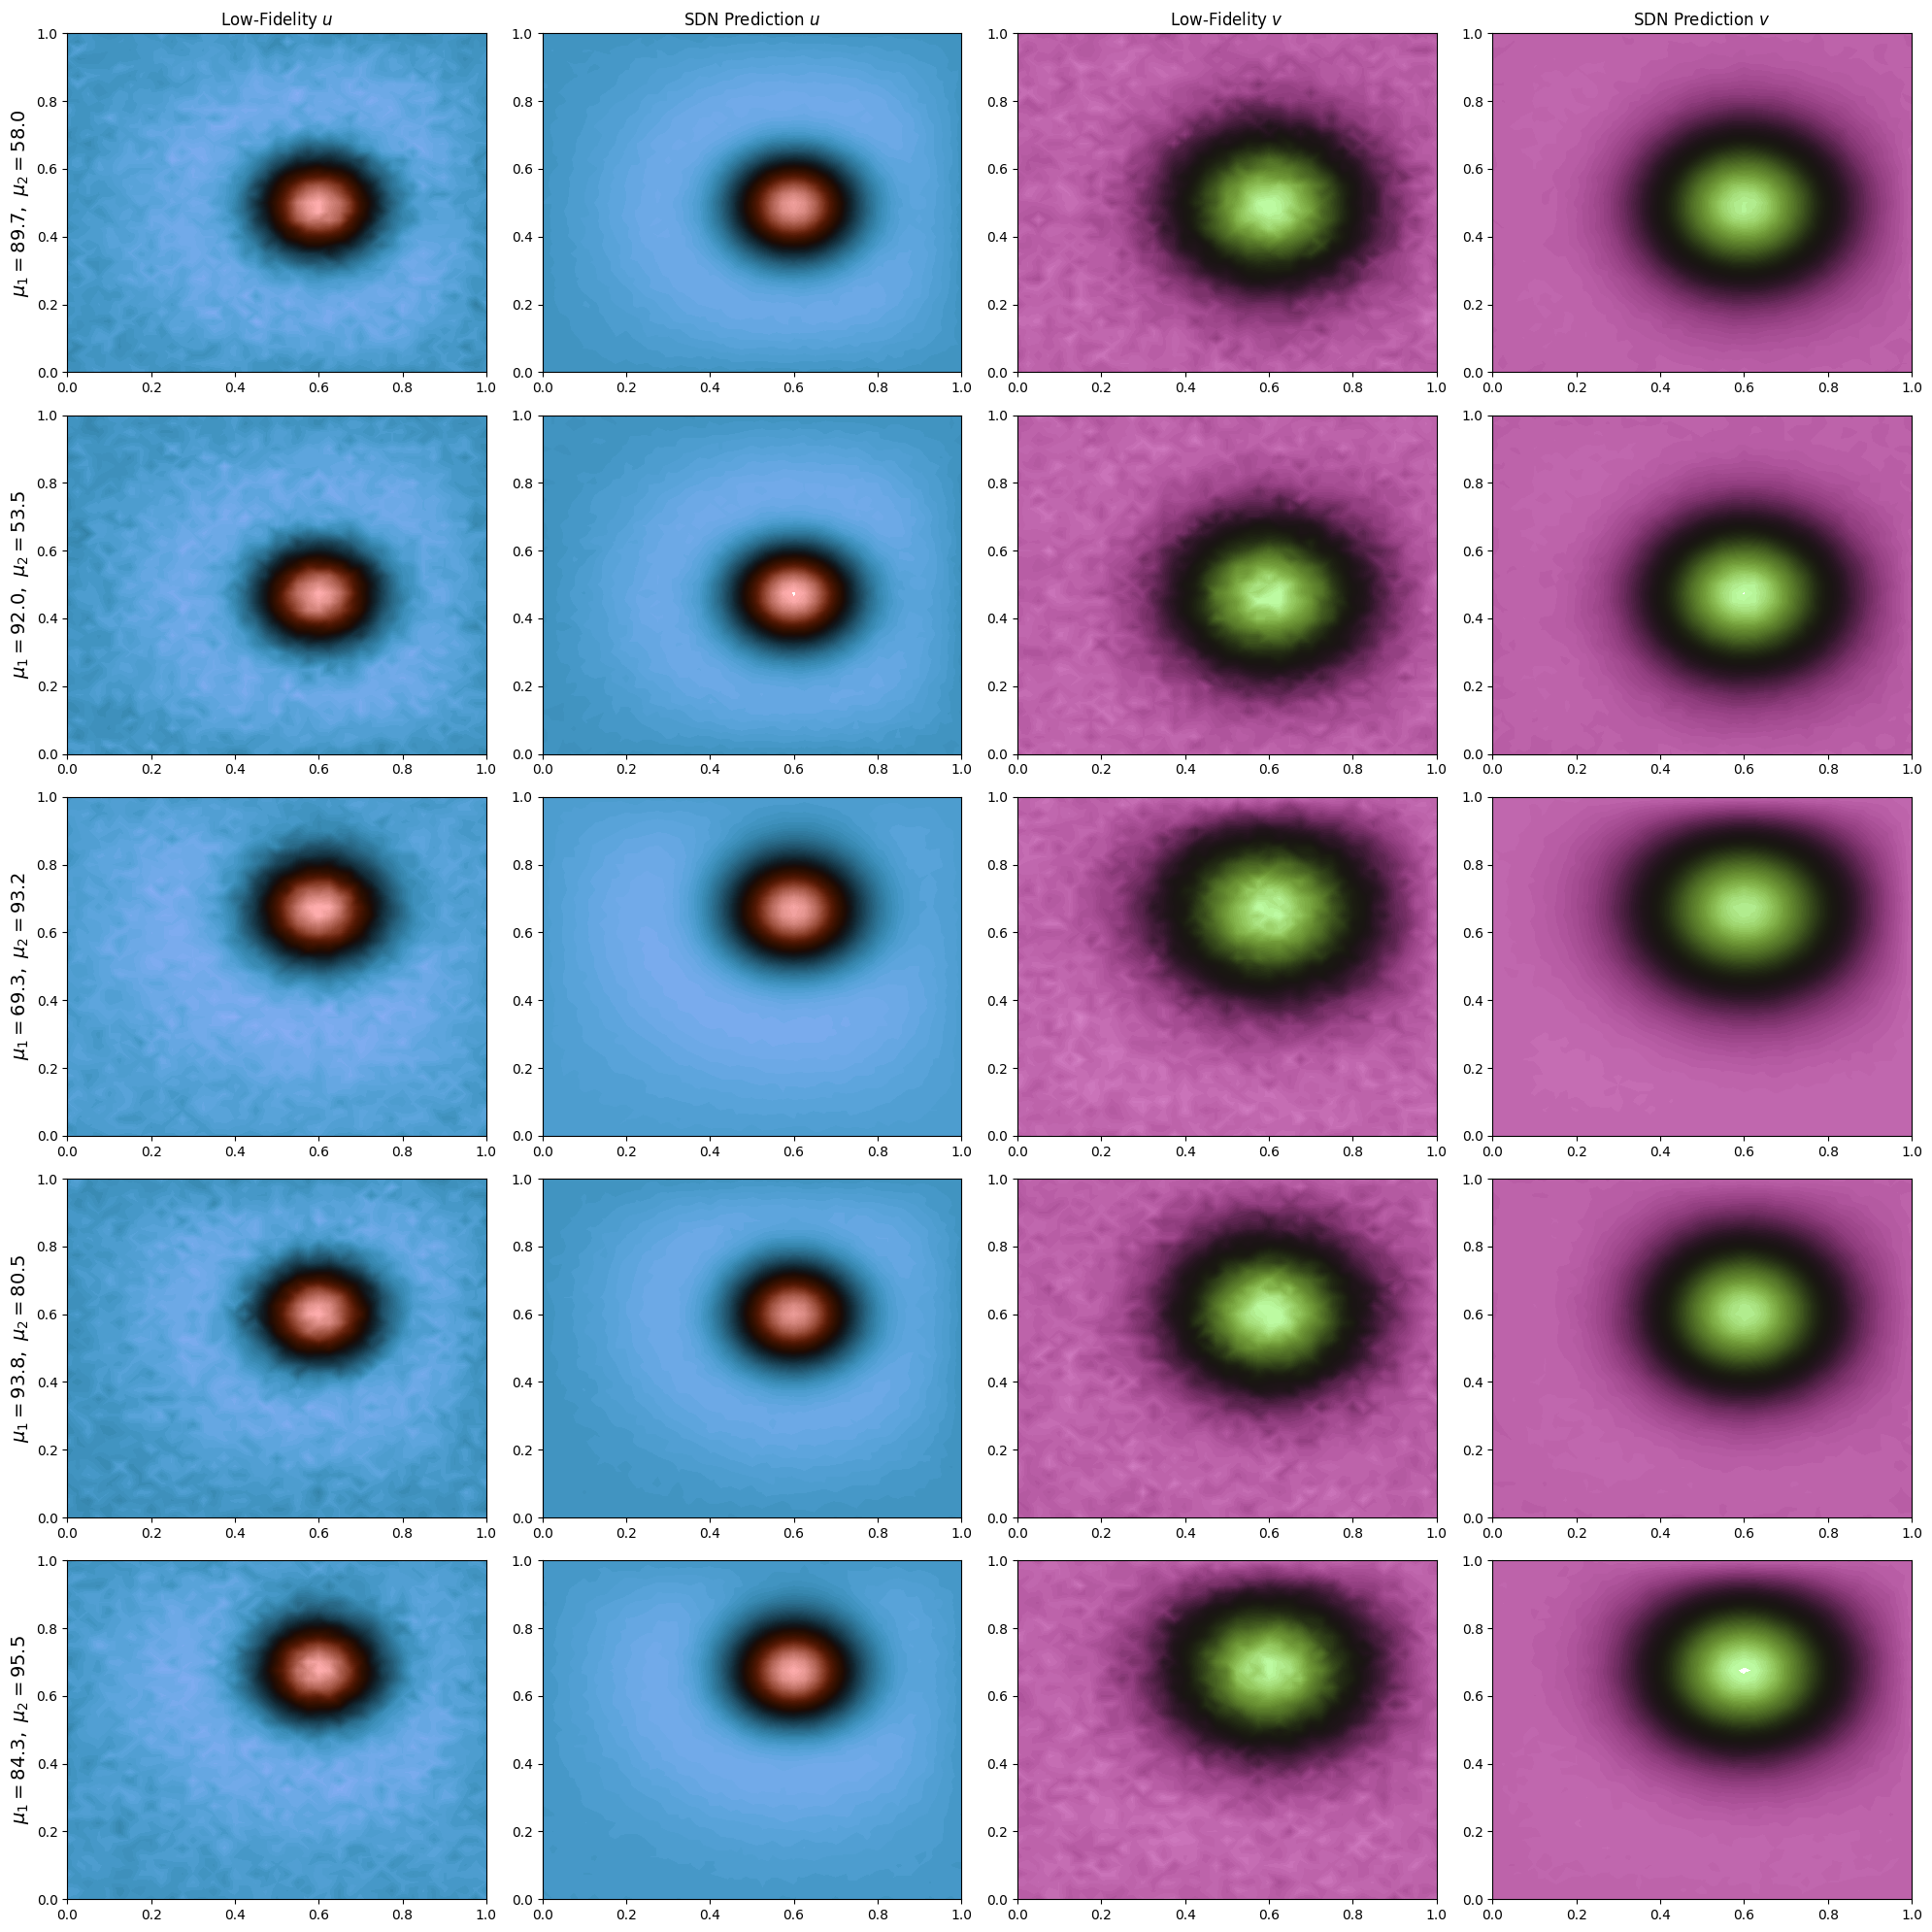

In [5]:
param_to_plot = np.sort(np.random.choice(lf_test_indices, size=min(5, len(lf_test_indices)), replace=False))
fig, axs = plt.subplots(len(param_to_plot), 4, figsize=(5 * 4, 4 * len(param_to_plot)))

for ii, idx in enumerate(param_to_plot):
    row = int(np.where(lf_test_indices == idx)[0][0])
    fom = lf_test_dataset.Y[row].cpu().numpy()
    model_pred = lf_sdn(lf_test_dataset.X[row]).cpu().detach().numpy()
    levels_u1 = np.linspace(0, np.max(fom[::2]), 100)
    levels_u2 = np.linspace(0, np.max(fom[1::2]), 100)
    axs[ii, 0].tricontourf(domain[:, 0], domain[:, 1], fom[::2], levels=levels_u1, cmap=cmaps[0])
    axs[ii, 1].tricontourf(domain[:, 0], domain[:, 1], model_pred[::2], levels=levels_u1, cmap=cmaps[0])
    axs[ii, 2].tricontourf(domain[:, 0], domain[:, 1], fom[1::2], levels=levels_u2, cmap=cmaps[1])
    axs[ii, 3].tricontourf(domain[:, 0], domain[:, 1], model_pred[1::2], levels=levels_u2, cmap=cmaps[1])
    mu1, mu2 = lf_params[idx]
    axs[ii, 0].set_ylabel(rf'$\mu_1={mu1:.1f},\ \mu_2={mu2:.1f}$', fontsize=14)

axs[0, 0].set_title('Low-Fidelity $u$')
axs[0, 1].set_title('SDN Prediction $u$')
axs[0, 2].set_title('Low-Fidelity $v$')
axs[0, 3].set_title('SDN Prediction $v$')
plt.tight_layout()
plt.show()


## Mapping Low Fidelity to High Fidelity
Let us build a residual network able to correct the missing physics of the surrogate model trained with the LF data.

Let us obtain some solutions of the HF and LF for new parameters

In [6]:
hf_params = sample_parameters(N_HF_SAMPLES, bounds=PARAM_BOUNDS, seed=2)

print('Solving HF snapshots')
hf_snaps = []
for mu1, mu2 in hf_params:
    sol, _ = solve(mu1=mu1, mu2=mu2, hf=True)
    hf_snaps.append(sol)
hf_snaps = np.array(hf_snaps).T
hf_snaps = (hf_snaps - _min) / (_max - _min)

print('Solving LF snapshots for MF comparison')
lf_snaps_comparison = []
for mu1, mu2 in hf_params:
    sol, _ = solve(mu1=mu1, mu2=mu2, hf=False)
    lf_snaps_comparison.append(sol)
lf_snaps_comparison = np.array(lf_snaps_comparison).T
lf_snaps_comparison = (lf_snaps_comparison - _min) / (_max - _min)
lf_snaps_comparison += np.random.normal(0, 0.01, lf_snaps_comparison.shape)
print(f'HF/LF comparison pool: {hf_params.shape[0]} parameter pairs')


Solving HF snapshots
Solving LF snapshots for MF comparison
HF/LF comparison pool: 200 parameter pairs


Let us define the input vector for the LF-SDN, composed by the parameter $\mu$ and 3 random measurements

In [7]:
_input = np.concatenate([lf_snaps_comparison[lf_idx_sens_locs], hf_params.T], axis=0)
_input = lf_input_scaler.transform(_input.T).T
_input = torch.tensor(_input, dtype=torch.float32).to(device).T
lf_sdn_pred = lf_sdn(_input).cpu().detach().numpy().T


Use **10 HF training snapshots** and a **100-sample test set** (50% of the comparison pool) for statistically richer MF evaluation.


In [10]:
np.random.seed(42)
train_indices, test_indices = train_test_split(
    np.arange(len(hf_params)), test_size=0.9, random_state=42
)
train_indices, valid_indices = train_test_split(train_indices, test_size=0.2, random_state=42)

hf_params_lhs = hf_params
hf_snaps_lhs = hf_snaps
lf_snaps_lhs = lf_snaps_comparison

print(f'Train: {len(train_indices)}, Valid: {len(valid_indices)}, Test: {len(test_indices)}')

_input = np.concatenate([lf_snaps_lhs[lf_idx_sens_locs], hf_params_lhs.T], axis=0)
_input = lf_input_scaler.transform(_input.T).T
_input = torch.tensor(_input, dtype=torch.float32).to(device).T

lf_sdn_red_coeff = lf_sdn.forward_pod(_input).cpu().detach().numpy()

train_input = lf_sdn_red_coeff[train_indices]
test_input = lf_sdn_red_coeff[test_indices]
valid_input = lf_sdn_red_coeff[valid_indices]

hf_input_scaler = MinMaxScaler().fit(train_input)
train_input = hf_input_scaler.transform(train_input)
test_input = hf_input_scaler.transform(test_input)
valid_input = hf_input_scaler.transform(valid_input)


Train: 16, Valid: 4, Test: 180


Let us define the dataset for the ResidualSDN and the net itself, still as a shallow decoder network without compressive training.

In [11]:
from utils.mf_sdn import CorrectionDataset, ResidualSDNetwork

# Define the datasets

train_delta_dataset = CorrectionDataset(
    torch.tensor(train_input, dtype=torch.float32).to(device),
    lf_sdn(_input)[train_indices].detach().clone(), 
    torch.tensor(hf_snaps_lhs[:, train_indices].T, dtype=torch.float32).to(device)
)
test_delta_dataset = CorrectionDataset(
    torch.tensor(test_input, dtype=torch.float32).to(device),
    lf_sdn(_input)[test_indices].detach().clone(),
    torch.tensor(hf_snaps_lhs[:, test_indices].T, dtype=torch.float32).to(device)
)
valid_delta_dataset = CorrectionDataset(
    torch.tensor(valid_input, dtype=torch.float32).to(device),
    lf_sdn(_input)[valid_indices].detach().clone(),
    torch.tensor(hf_snaps_lhs[:, valid_indices].T, dtype=torch.float32).to(device)
)

# Define the Residual SDN
in_dim = train_input.shape[1]
out_dim = hf_snaps_lhs.shape[0]
residual_sdn = ResidualSDNetwork(in_dim=in_dim, out_dim=out_dim, dropout=0.1, decoder_sizes=[350, 400]).to(device)

Let us train the ResidualSDN using a L1 loss function

Residual SDN training time: 4.60 s.1174e-03 Validation Loss 8.2835e-03


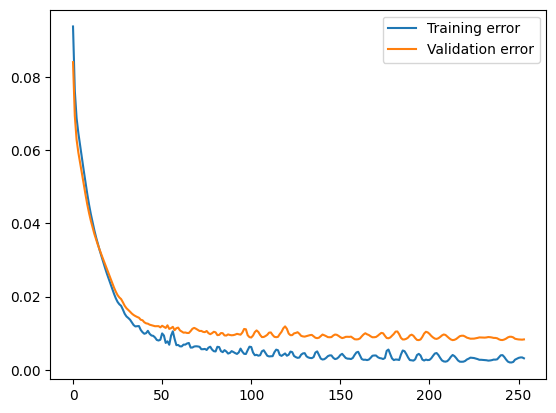

In [12]:
import time
import torch.nn as nn
from utils.mf_sdn import fit_res

loss_function = nn.L1Loss()

start = time.perf_counter()
train_res_errors, valid_res_errors = fit_res(
    model=residual_sdn,
    train_dataset=train_delta_dataset,
    valid_dataset=valid_delta_dataset,
    batch_size=32,
    epochs=500,
    patience=40,
    optim=torch.optim.Adam,
    criterion=loss_function,
    lr=0.0001,
    verbose=True,
)
residual_sdn_train_time = time.perf_counter() - start
print(f'Residual SDN training time: {residual_sdn_train_time:.2f} s')

plt.plot(train_res_errors, label='Training error')
plt.plot(valid_res_errors, label='Validation error')
plt.legend()


## Tier B classical MF baselines

Two-parameter setup ($\mu_1, \mu_2$) with **100 test snapshots** (50% of the 200-sample HF pool). Baselines:

| Method | Inputs | Notes |
|--------|--------|-------|
| **Linear-MF** | LF POD coeffs `v_LF` (dim 12) | Ridge on full-state residual |
| **GP-residual** | `v_LF` | GP on POD residual; harder in 12-D input |
| **Co-kriging** | $(\mu_1, \mu_2)$ + LF field | Autoregressive MF-GP in POD space |
| **SDN-MF** | `v_LF` | Nonlinear residual decoder |

Metrics report **mean $\pm$ std** of per-sample relative errors over the test set.


In [13]:
import time
import pandas as pd
from utils.mf_baselines import (
    LinearMFCorrector,
    PODGPRResidualCorrector,
    CoKrigingMFCorrector,
    evaluate_mf_methods,
)

v_lf_train = train_delta_dataset.v_LF
u_lf_train = train_delta_dataset.u_LF
u_hf_train = train_delta_dataset.u_HF
mu_train = hf_params_lhs[train_indices]

v_lf_test = test_delta_dataset.v_LF
u_lf_test = test_delta_dataset.u_LF
mu_test = hf_params_lhs[test_indices]
n_test = len(test_indices)
n_timing_repeat = 20

start = time.perf_counter()
linear_mf = LinearMFCorrector(alpha=1e-6).fit(v_lf_train, u_lf_train, u_hf_train)
linear_fit_s = time.perf_counter() - start
start = time.perf_counter()
for _ in range(n_timing_repeat):
    pred_linear = linear_mf.predict(v_lf_test, u_lf_test).T
linear_predict_s = (time.perf_counter() - start) / n_timing_repeat

start = time.perf_counter()
gp_residual = PODGPRResidualCorrector(rank=pod_rank, alpha=1e-4).fit(v_lf_train, u_lf_train, u_hf_train)
gp_fit_s = time.perf_counter() - start
start = time.perf_counter()
for _ in range(n_timing_repeat):
    pred_gp = gp_residual.predict(v_lf_test, u_lf_test).T
gp_predict_s = (time.perf_counter() - start) / n_timing_repeat

start = time.perf_counter()
cokriging_mf = CoKrigingMFCorrector(rank=pod_rank, alpha=1e-4).fit(mu_train, u_lf_train, u_hf_train)
cokrig_fit_s = time.perf_counter() - start
start = time.perf_counter()
for _ in range(n_timing_repeat):
    pred_cokriging = cokriging_mf.predict(mu_test, u_lf_test).T
cokrig_predict_s = (time.perf_counter() - start) / n_timing_repeat

start = time.perf_counter()
for _ in range(n_timing_repeat):
    pred_sdn = (residual_sdn(test_delta_dataset.v_LF) + test_delta_dataset.u_LF).cpu().detach().numpy().T
residual_sdn_predict_time = (time.perf_counter() - start) / n_timing_repeat

test_hf_fom = test_delta_dataset.u_HF.cpu().numpy().T
test_lf_fom = test_delta_dataset.u_LF.cpu().numpy().T

mf_metrics = evaluate_mf_methods(
    test_hf_fom,
    {
        'Linear-MF': pred_linear,
        'GP-residual': pred_gp,
        'Co-kriging': pred_cokriging,
        'SDN-MF': pred_sdn,
    },
    reference_lf=test_lf_fom,
)

mf_summary = pd.DataFrame({
    'rel-L2 mean': [mf_metrics[m]['l2'] for m in ['LF','Linear-MF','GP-residual','Co-kriging','SDN-MF']],
    'rel-L2 std': [np.std(mf_metrics[m]['l2_per_sample']) for m in ['LF','Linear-MF','GP-residual','Co-kriging','SDN-MF']],
    'rel-max mean': [mf_metrics[m]['max'] for m in ['LF','Linear-MF','GP-residual','Co-kriging','SDN-MF']],
    'rel-max std': [np.std(mf_metrics[m]['max_per_sample']) for m in ['LF','Linear-MF','GP-residual','Co-kriging','SDN-MF']],
}, index=['LF','Linear-MF','GP-residual','Co-kriging','SDN-MF'])
display(mf_summary)

mf_costs = pd.DataFrame(
    {
        'fit [s]': [linear_fit_s, gp_fit_s, cokrig_fit_s, residual_sdn_train_time],
        'predict [s]': [linear_predict_s, gp_predict_s, cokrig_predict_s, residual_sdn_predict_time],
        'predict / sample [ms]': [
            1e3 * linear_predict_s / n_test,
            1e3 * gp_predict_s / n_test,
            1e3 * cokrig_predict_s / n_test,
            1e3 * residual_sdn_predict_time / n_test,
        ],
    },
    index=['Linear-MF', 'GP-residual', 'Co-kriging', 'SDN-MF'],
)
display(mf_costs)

best_l2 = mf_summary['rel-L2 mean'].drop('LF').idxmin()
print(f'Test set size: {n_test} | Best mean rel-L2: {best_l2} ({mf_summary.loc[best_l2, "rel-L2 mean"]:.4e})')


/opt/miniconda3/envs/ml/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/miniconda3/envs/ml/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/miniconda3/envs/ml/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/opt/miniconda3/envs/ml/lib/python3.10/site-packages/sklearn/linear_model/_base.py:314: RuntimeWarning: divide by zero encountered in matmul
  intercept_ = y_offset - X_offset @ coef_.T
/opt/miniconda3/envs/ml/lib/python3.10/site-packages/sklearn/linear_model/_base.py:314: RuntimeWarning: overflow encountered in matmul
  intercept_ = y_offset - X_offset @ coef_.T
/opt/miniconda3/envs/ml/lib/python3.10/site-packages/sklearn/linear_model/_base.py:314: RuntimeWarning: invalid value encountered in matmul
  intercept_ = y_offset - X_offset @ coef_.T
/opt/m

,rel-L2 mean,rel-L2 std,rel-max mean,rel-max std
LF,0.456714,0.015007,0.822174,0.086136
Linear-MF,0.032031,0.034354,0.055020,0.056009
GP-residual,0.020742,0.013790,0.035576,0.023753
Co-kriging,0.017161,0.009262,0.031372,0.019002
SDN-MF,0.053503,0.035221,0.104268,0.061150


,fit [s],predict [s],predict / sample [ms]
Linear-MF,0.007470,0.001546,0.008589
GP-residual,0.070603,0.003154,0.017522
Co-kriging,0.087250,0.002183,0.012130
SDN-MF,4.595041,0.003696,0.020531


Test set size: 180 | Best mean rel-L2: Co-kriging (1.7161e-02)


Let us plot the output of the residual network

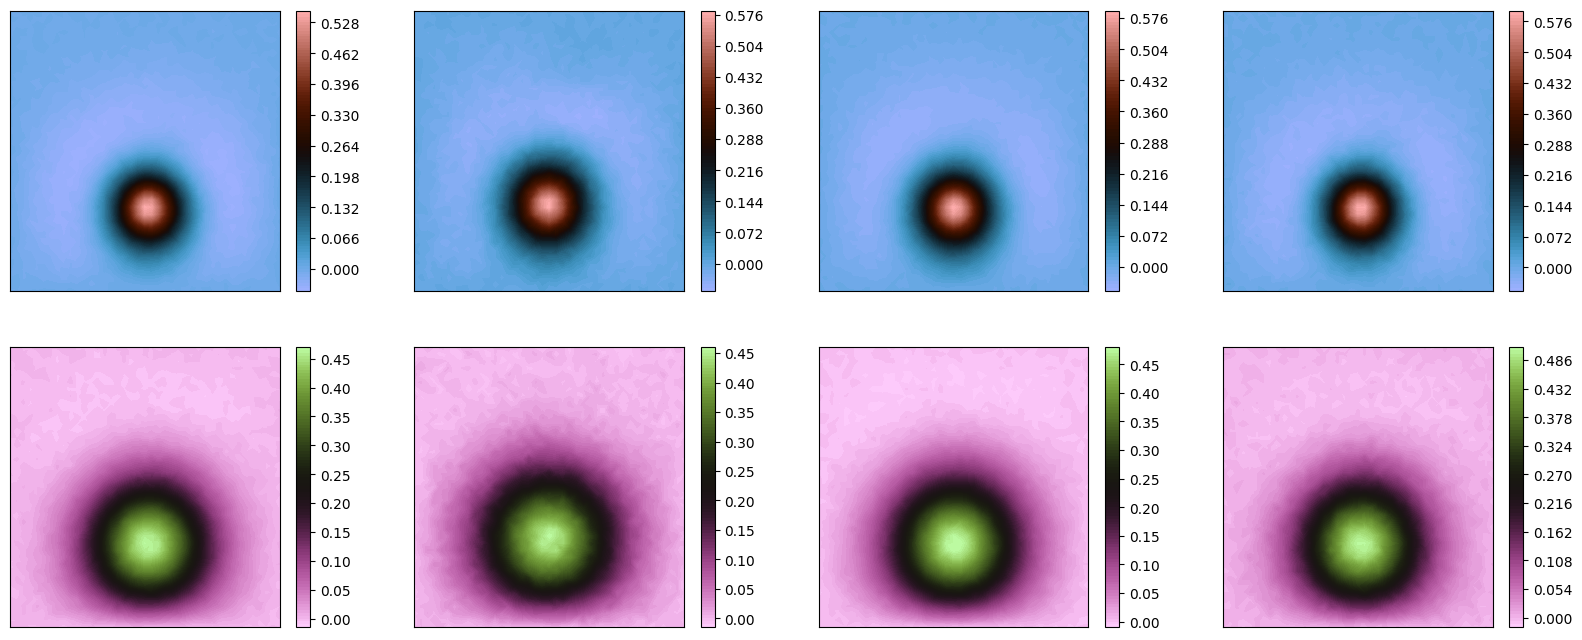

In [14]:
res_net_out = residual_sdn(test_delta_dataset.v_LF).cpu().detach().numpy()

test_to_plot = np.random.choice(res_net_out.shape[0], size=min(4, len(test_indices)), replace=False)

fig, axs = plt.subplots(2, len(test_to_plot), figsize=(5 * len(test_to_plot), 8))

for ii in range(len(test_to_plot)):
    _idx = test_to_plot[ii]
    cont = axs[0, ii].tricontourf(domain[:, 0], domain[:, 1], res_net_out[_idx, ::2], levels=100, cmap=cmaps[0])
    fig.colorbar(cont, ax=axs[0, ii])
    cont2 = axs[1, ii].tricontourf(domain[:, 0], domain[:, 1], res_net_out[_idx, 1::2], levels=100, cmap=cmaps[1])
    fig.colorbar(cont2, ax=axs[1, ii])

for ax in axs.flatten():
    ax.set_xticks([])
    ax.set_yticks([])  

### Accuracy and computational cost

With two parameters and **100 test snapshots**, we report mean $\pm$ std per-sample errors (boxplots below) rather than a single aggregate norm.

**Why this is harder than the 1D-$\mu$ case:**
- Input dimension increases (12 POD coeffs vs 10, plus 2 physical parameters in co-kriging).
- GP-residual must learn over a 2D parameter manifold embedded in 12-D `v_LF` space.
- SDN-MF can leverage global nonlinear structure; co-kriging uses $\mu$ directly but only linearly couples fidelities per POD mode.

Re-run the cells above to refresh results on your hardware.


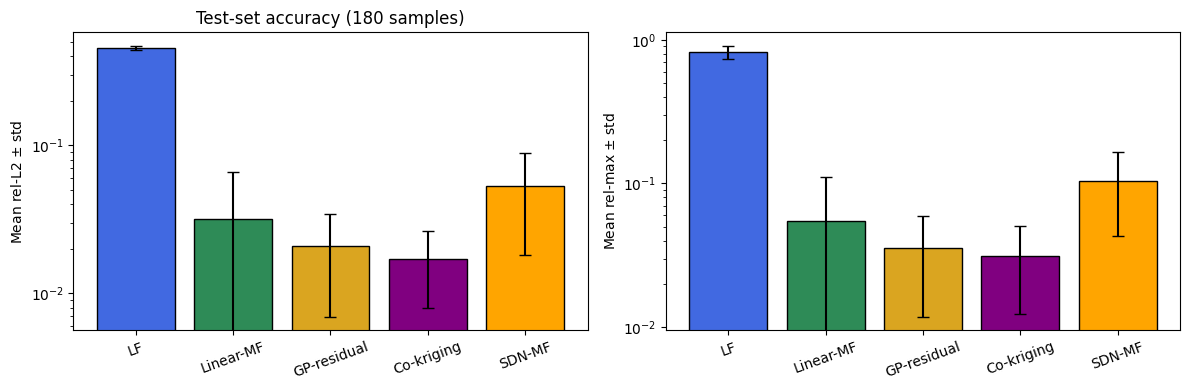

In [15]:
methods = ['LF', 'Linear-MF', 'GP-residual', 'Co-kriging', 'SDN-MF']
colors = ['royalblue', 'seagreen', 'goldenrod', 'purple', 'orange']

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
means_l2 = [mf_summary.loc[m, 'rel-L2 mean'] for m in methods]
stds_l2 = [mf_summary.loc[m, 'rel-L2 std'] for m in methods]
means_max = [mf_summary.loc[m, 'rel-max mean'] for m in methods]
stds_max = [mf_summary.loc[m, 'rel-max std'] for m in methods]

axs[0].bar(methods, means_l2, yerr=stds_l2, color=colors, edgecolor='black', capsize=4)
axs[0].set_ylabel('Mean rel-L2 $\pm$ std')
axs[0].set_yscale('log')
axs[0].set_title(f'Test-set accuracy ({n_test} samples)')
axs[0].tick_params(axis='x', rotation=20)

axs[1].bar(methods, means_max, yerr=stds_max, color=colors, edgecolor='black', capsize=4)
axs[1].set_ylabel('Mean rel-max $\pm$ std')
axs[1].set_yscale('log')
axs[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()


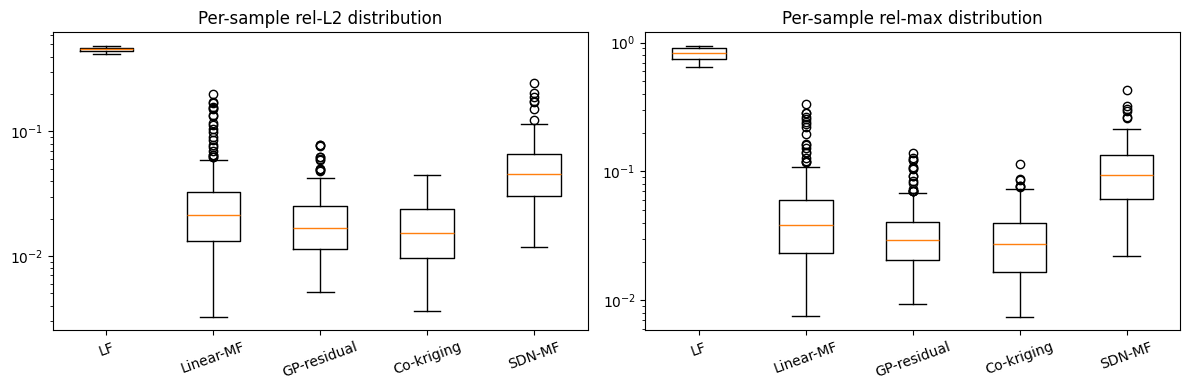

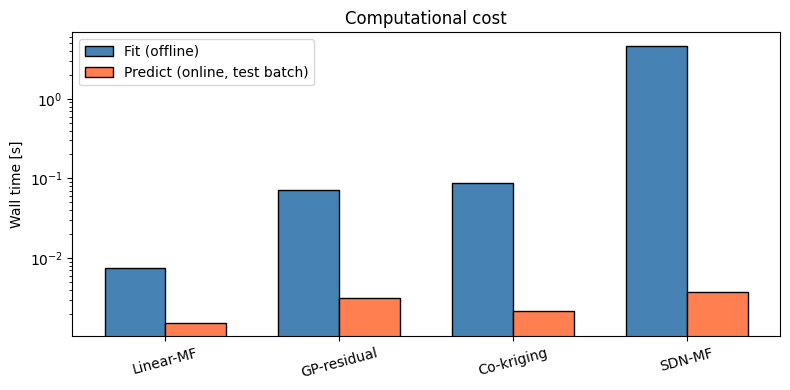

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
box_data_l2 = [mf_metrics[m]['l2_per_sample'] for m in methods]
box_data_max = [mf_metrics[m]['max_per_sample'] for m in methods]

axs[0].boxplot(box_data_l2, tick_labels=methods)
axs[0].set_yscale('log')
axs[0].set_title('Per-sample rel-L2 distribution')
axs[0].tick_params(axis='x', rotation=20)

axs[1].boxplot(box_data_max, tick_labels=methods)
axs[1].set_yscale('log')
axs[1].set_title('Per-sample rel-max distribution')
axs[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

cost_methods = ['Linear-MF', 'GP-residual', 'Co-kriging', 'SDN-MF']
fit_times = mf_costs.loc[cost_methods, 'fit [s]'].values
pred_times = mf_costs.loc[cost_methods, 'predict [s]'].values
x = np.arange(len(cost_methods))
width = 0.35
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - width/2, fit_times, width, label='Fit (offline)', color='steelblue', edgecolor='black')
ax.bar(x + width/2, pred_times, width, label='Predict (online, test batch)', color='coral', edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels(cost_methods, rotation=15)
ax.set_ylabel('Wall time [s]')
ax.set_yscale('log')
ax.set_title('Computational cost')
ax.legend()
plt.tight_layout()
plt.show()


Let us plot the results on the test dataset

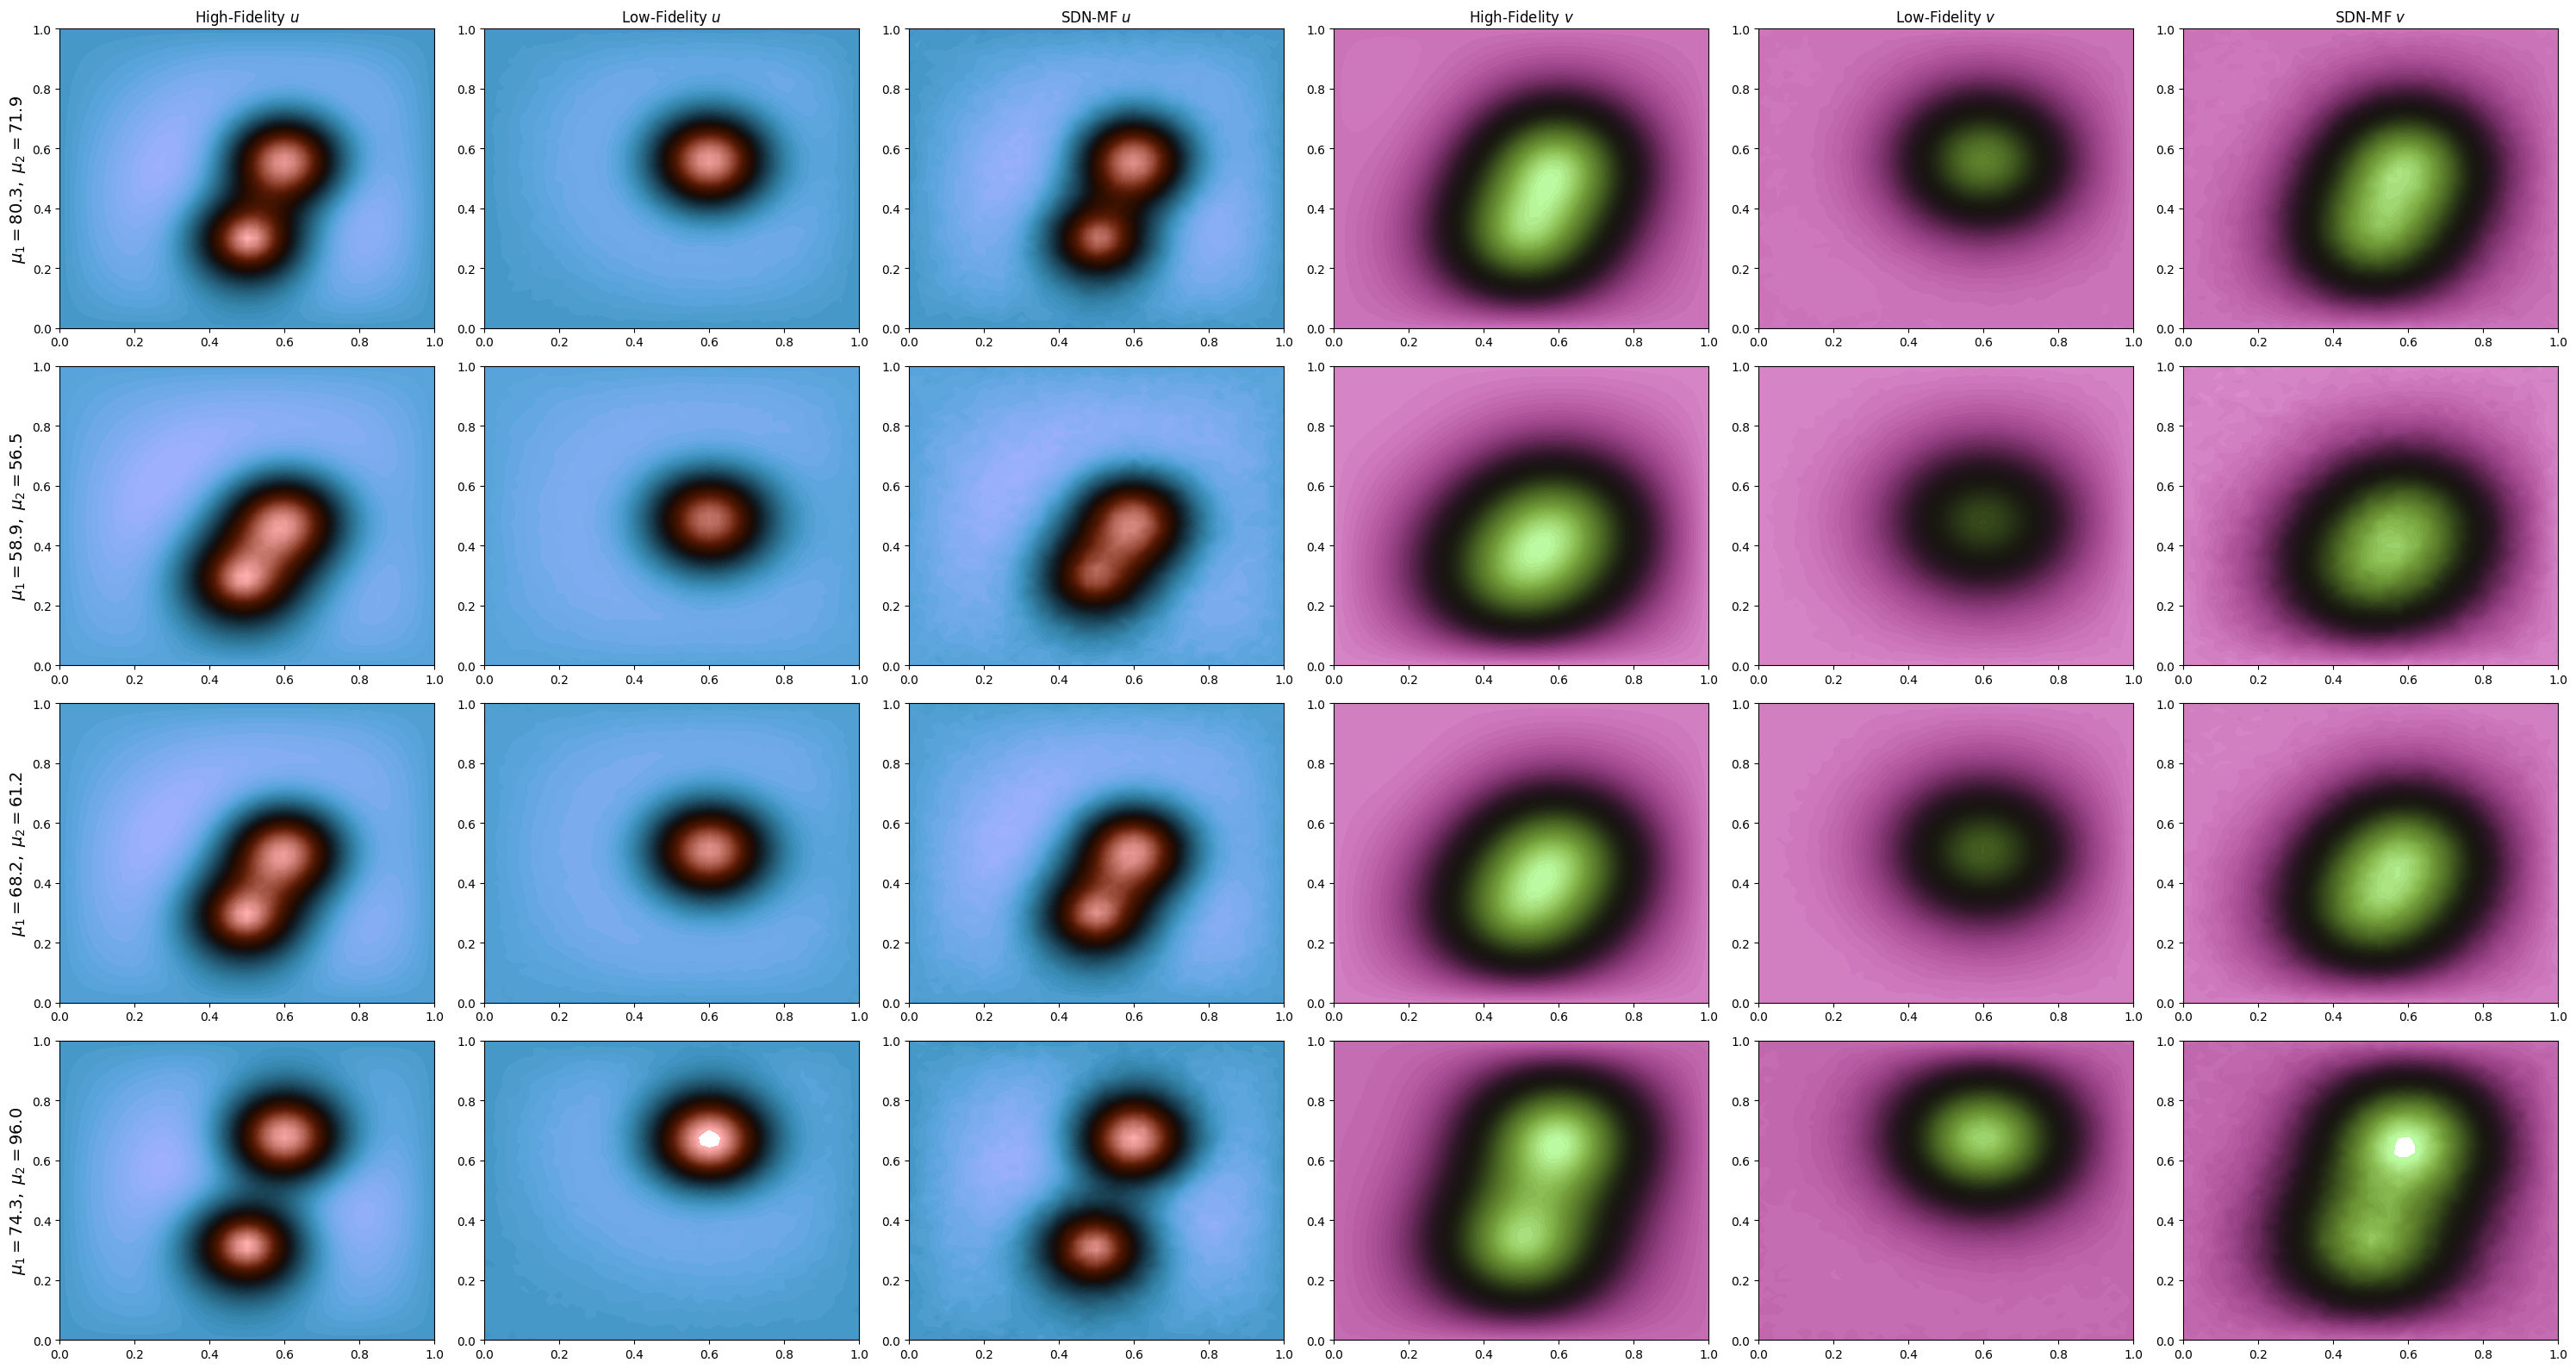

In [17]:
n_plot = min(4, len(test_indices))
plot_idx = test_indices[:n_plot]
fig, axs = plt.subplots(n_plot, 6, figsize=(5 * 6, 4 * n_plot))
if n_plot == 1:
    axs = axs.reshape(1, -1)

for ii, param_idx in enumerate(plot_idx):
    fom = test_hf_fom[:, ii]
    fom_lf = test_lf_fom[:, ii]
    model_pred = pred_sdn[:, ii]
    levels_u1 = np.linspace(0, np.max(fom[::2]), 100)
    levels_u2 = np.linspace(0, np.max(fom[1::2]), 100)
    axs[ii, 0].tricontourf(domain[:, 0], domain[:, 1], fom[::2], levels=levels_u1, cmap=cmaps[0])
    axs[ii, 1].tricontourf(domain[:, 0], domain[:, 1], fom_lf[::2], levels=levels_u1, cmap=cmaps[0])
    axs[ii, 2].tricontourf(domain[:, 0], domain[:, 1], model_pred[::2], levels=levels_u1, cmap=cmaps[0])
    axs[ii, 3].tricontourf(domain[:, 0], domain[:, 1], fom[1::2], levels=levels_u2, cmap=cmaps[1])
    axs[ii, 4].tricontourf(domain[:, 0], domain[:, 1], fom_lf[1::2], levels=levels_u2, cmap=cmaps[1])
    axs[ii, 5].tricontourf(domain[:, 0], domain[:, 1], model_pred[1::2], levels=levels_u2, cmap=cmaps[1])
    mu1, mu2 = hf_params_lhs[param_idx]
    axs[ii, 0].set_ylabel(rf'$\mu_1={mu1:.1f},\ \mu_2={mu2:.1f}$', fontsize=14)

axs[0, 0].set_title('High-Fidelity $u$')
axs[0, 1].set_title('Low-Fidelity $u$')
axs[0, 2].set_title('SDN-MF $u$')
axs[0, 3].set_title('High-Fidelity $v$')
axs[0, 4].set_title('Low-Fidelity $v$')
axs[0, 5].set_title('SDN-MF $v$')
plt.tight_layout()
plt.show()
